In [1]:
import cuml

from cuml.ensemble import RandomForestRegressor

from sklearn import ensemble
from sklearn.ensemble import ExtraTreesRegressor

import sklearn

import matplotlib.pyplot as plt

import xgboost as xgb
from lightgbm import LGBMRegressor

import torch

import numpy as np
import cupy as cp

import pandas as pd
from pathlib import Path
import gc

from sklearn.metrics import r2_score

import time

In [2]:
extrat = True
xgboost = True
lgboostm = True

In [3]:
ET = {
    "model": ExtraTreesRegressor,
    "n_estimators": [50, 50, 50],
    "max_depth": [21, 21, 1],
    "min_samples_leaf": [4, 4, 2],
    "max_features": [1.0, 1.0, 0.1],
    "results": []
}

X = {
    "model": xgb,
    "n_estimators": [500, 500, 50],
    "max_depth": [15, 15, 1],
    "min_child_weight": [3, 3, 1],
    "results": []
}

LGBM = {
    "model": LGBMRegressor,
    "n_estimators": [450, 450, 50],
    "min_child_samples": [15, 15, 10],
    "num_leaves": [256, 256, 2],
    "colsample_bytree": [0.7, 0.7, 0.1],
    "results": [],
    "trials": []
}

In [4]:
datasetPath = Path("/home/philipm/Desktop/ML-For-CV-Robustness/datasets/trees-dl-aoi.csv")

#making sure
datasetPath.is_file()

True

In [5]:
dataset = pd.read_csv(datasetPath)
dataset.head()

,grviIn,meanRefR,meanRefG,illumR,illumG,blockIdx,sunRoll,sunPitch,sunYaw,camRoll,camPitch,camYaw,grviOut
0,0.210754,0.000179,0.000229,1136.471,1031.228,0.0,180.0,-71.945084,19.489212,0.0,-19.258,-0.0,0.116122
1,0.123970,0.000280,0.000321,1136.471,1031.228,1.0,180.0,-71.945084,19.489212,0.0,-19.258,-0.0,0.106717
2,0.092202,0.000341,0.000383,1136.471,1031.228,2.0,180.0,-71.945084,19.489212,0.0,-19.258,-0.0,0.097078
3,0.191730,0.000242,0.000306,1136.471,1031.228,3.0,180.0,-71.945084,19.489212,0.0,-19.258,-0.0,0.112769
4,0.145418,0.000262,0.000312,1136.471,1031.228,4.0,180.0,-71.945084,19.489212,0.0,-19.258,-0.0,0.103993


In [6]:
target_col = dataset["grviOut"]
labels = target_col.to_numpy(dtype="float32")
labels

array([0.1161218 , 0.10671729, 0.09707835, ..., 0.13551866, 0.13556816,
       0.14273934], shape=(333760,), dtype=float32)

In [7]:
inputs = dataset.drop("grviOut", axis=1)
inputs = inputs.drop("sunRoll", axis=1)
inputs = inputs.drop("camRoll", axis=1)

inputs.head()

,grviIn,meanRefR,meanRefG,illumR,illumG,blockIdx,sunPitch,sunYaw,camPitch,camYaw
0,0.210754,0.000179,0.000229,1136.471,1031.228,0.0,-71.945084,19.489212,-19.258,-0.0
1,0.123970,0.000280,0.000321,1136.471,1031.228,1.0,-71.945084,19.489212,-19.258,-0.0
2,0.092202,0.000341,0.000383,1136.471,1031.228,2.0,-71.945084,19.489212,-19.258,-0.0
3,0.191730,0.000242,0.000306,1136.471,1031.228,3.0,-71.945084,19.489212,-19.258,-0.0
4,0.145418,0.000262,0.000312,1136.471,1031.228,4.0,-71.945084,19.489212,-19.258,-0.0


In [8]:
inputs = inputs.to_numpy(dtype="float32")
inputs

array([[ 2.1075405e-01,  1.7945077e-04,  2.2896443e-04, ...,
         1.9489212e+01, -1.9257999e+01, -0.0000000e+00],
       [ 1.2397036e-01,  2.7967661e-04,  3.2067925e-04, ...,
         1.9489212e+01, -1.9257999e+01, -0.0000000e+00],
       [ 9.2202291e-02,  3.4122023e-04,  3.8319931e-04, ...,
         1.9489212e+01, -1.9257999e+01, -0.0000000e+00],
       ...,
       [ 2.3046868e-01,  1.0813908e-03,  1.6539922e-03, ...,
         1.0435840e+02, -2.2218000e+01, -1.8000000e+02],
       [ 2.3434559e-01,  9.0364768e-04,  1.3691875e-03, ...,
         1.0435840e+02, -2.2218000e+01, -1.8000000e+02],
       [ 2.4411118e-01,  8.7809877e-04,  1.3535006e-03, ...,
         1.0435840e+02, -2.2218000e+01, -1.8000000e+02]],
      shape=(333760, 10), dtype=float32)

In [9]:
n_total = len(inputs)

n_train = int(0.9*n_total)
n_val = int(0.1*n_total)

# shuffle
g = torch.Generator().manual_seed(42)
perm = torch.randperm(n_total, generator=g).numpy()

inputs_shuf = inputs[perm]
labels_shuf = labels[perm]

# split
train_inputs, train_labels = inputs_shuf[:n_train], labels_shuf[:n_train]
val_inputs, val_labels = inputs_shuf[n_train:n_train + n_val], labels_shuf[n_train:n_train + n_val]

In [10]:
from sklearn.preprocessing import QuantileTransformer, StandardScaler

if True:
    input_scaler = StandardScaler() #QuantileTransformer(output_distribution='normal')
    target_scaler = StandardScaler()

    train_inputs = input_scaler.fit_transform(train_inputs)
    val_inputs = input_scaler.transform(val_inputs)

In [11]:
# pca time

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA()
trainPCA = pca.fit_transform(train_inputs)

print(pca.explained_variance_ratio_)
print(pca.explained_variance_ratio_.cumsum())

[2.82698601e-01 1.20424092e-01 1.08483456e-01 1.03704736e-01
 1.00254275e-01 9.95028391e-02 9.24447849e-02 9.12376195e-02
 9.67216329e-04 2.82395864e-04]
[0.2826986  0.4031227  0.51160616 0.6153109  0.7155652  0.81506807
 0.90751284 0.99875045 0.99971765 1.        ]


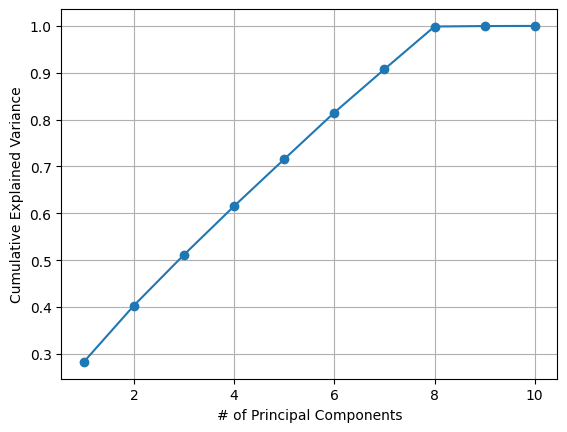

In [12]:
plt.plot (
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_.cumsum(),
    marker="o"
)

plt.xlabel("# of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.grid()
plt.show()

In [13]:
pca = PCA(n_components=0.95)

train_inputs = pca.fit_transform(train_inputs)
val_inputs = pca.transform(val_inputs)

In [14]:
ne = ET["n_estimators"][0]
md = ET["max_depth"][0]
nb = ET["min_samples_leaf"][0]
mf = ET["max_features"][0]

modelET = ET["model"](n_estimators=ne, max_depth=md, min_samples_leaf=nb, max_features=mf)
modelET.fit(train_inputs, train_labels)

y_pred = modelET.predict(val_inputs)

rmse = np.sqrt(cuml.metrics.mean_squared_error(val_labels, y_pred))
r2 = r2_score(val_labels, y_pred)

rel_test_loss = (rmse*100) / (val_labels.max()-val_labels.min())

print ("overall: RelRMSE: " + str(float(rel_test_loss)) + "%, " + "r2 " + str(r2))

overall: RelRMSE: 12.910936812876331%, r2 0.37464734418276724


In [15]:
ne = X["n_estimators"][0]
md = X["max_depth"][0]
mc = X["min_child_weight"][0]

modelXGB = X["model"].XGBRegressor(n_estimators=ne, max_depth=md, min_child_weight=mc, learning_rate=0.05, tree_method="gpu_hist", gpu_id=0)
modelXGB.fit(train_inputs, train_labels)

y_pred = modelXGB.predict(val_inputs)

rmse = np.sqrt(cuml.metrics.mean_squared_error(val_labels, y_pred))
r2 = r2_score(val_labels, y_pred)

rel_test_loss = (rmse*100) / (val_labels.max()-val_labels.min())

print ("overall: RelRMSE: " + str(float(rel_test_loss)) + "%, " + "r2 " + str(r2))

overall: RelRMSE: 10.629940403378848%, r2 0.5760924816131592


In [16]:
ne = LGBM["n_estimators"][0]
mcs = LGBM["min_child_samples"][0]
nl = LGBM["num_leaves"][0]
cb = LGBM["colsample_bytree"][0]

modelLGBM = LGBM["model"](n_estimators=ne, min_child_samples=mcs, num_leaves=nl-1, colsample_bytree=cb)
modelLGBM.fit(train_inputs, train_labels)

y_pred = modelLGBM.predict(val_inputs)

rmse = np.sqrt(cuml.metrics.mean_squared_error(val_labels, y_pred))
r2 = r2_score(val_labels, y_pred)

rel_test_loss = (rmse*100) / (val_labels.max()-val_labels.min())

print ("overall: RelRMSE: " + str(float(rel_test_loss)) + "%, " + "r2 " + str(r2))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004924 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 300384, number of used features: 8
[LightGBM] [Info] Start training from score 0.155433
overall: RelRMSE: 11.304352431103133%, r2 0.5205968701948838


In [17]:
val_inputs[1].shape

(8,)